Predicting Air Quality based on environmental measurements

In [21]:
#Install the ucimlrepo package
!pip install ucimlrepo


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
#Import the dataset
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
air_quality = fetch_ucirepo(id=360) 
  
# metadata 
print(air_quality.metadata) 
  
# variable information 
print(air_quality.variables) 


{'uci_id': 360, 'name': 'Air Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/360/air+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/360/data.csv', 'abstract': 'Contains the responses of a gas multisensor device deployed on the field in an Italian city. Hourly responses averages are recorded along with gas concentrations references from a certified analyzer. ', 'area': 'Computer Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 9358, 'num_features': 15, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Sun Mar 10 2024', 'dataset_doi': '10.24432/C59K5F', 'creators': ['Saverio Vito'], 'intro_paper': {'ID': 420, 'type': 'NATIVE', 'title': 'On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario', 'authors': 

Variables meaning	
CO(GT)	  Carbon monoxide concentration   -Direct pollution indicator
NOx(GT)	  Nitrogen oxides concentration   -Direct pollution indicator
NO2(GT)	  Nitrogen dioxide concentration  -Direct pollution indicator
T	      Temperature                     -Meteorological context
RH	      Relative humidity               -Meteorological context

NOTE:
CO, NOx and NO₂ measure pollution. Temperature and relative humidity influence atmospheric conditions but are not direct measures of pollution.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from matplotlib.colors import ListedColormap

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [24]:
# Create DataFrame
df = air_quality.data.original.copy()

# Explore dataset
display(df.head())

df.info()

display(df.describe())

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   int64  
 4   NMHC(GT)       9357 non-null   int64  
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   int64  
 7   NOx(GT)        9357 non-null   int64  
 8   PT08.S3(NOx)   9357 non-null   int64  
 9   NO2(GT)        9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(5), int64(8), str(2)
memory usage: 1.2 MB


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


TO Clean the dataset:
The UCI dataset uses -200 to represent missing measurements. 
These values must be converted to actual missing values before cleaning

In [25]:
# Replace -200 with NaN
df.replace(-200, np.nan, inplace=True)

# Keep only the variables needed
df = df[
    ['Date', 'CO(GT)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH']
].copy()

# Remove missing values
df.dropna(inplace=True)

# Remove duplicates
df.drop_duplicates(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

# Check cleaning
print("Remaining rows:", len(df))
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

Remaining rows: 6941
Missing values: 0
Duplicates: 0


In [26]:
#Group observations by date
daily_df = df.groupby('Date').agg({
    'CO(GT)': 'mean',
    'NOx(GT)': 'mean',
    'NO2(GT)': 'mean',
    'T': 'mean',
    'RH': 'mean'
}).reset_index()

In [27]:
daily_df.rename(columns={
    'CO(GT)': 'CO',
    'NOx(GT)': 'NOx',
    'NO2(GT)': 'NO2'
}, inplace=True)

display(daily_df.head())

,Date,CO,NOx,NO2,T,RH
0,1/1/2005,2.109091,311.181818,128.409091,6.900000,51.140909
1,1/10/2005,2.185714,413.952381,129.809524,13.404762,68.280952
2,1/11/2005,2.895652,432.913043,131.217391,12.765217,64.034783
3,1/12/2005,3.372727,577.136364,151.863636,12.045455,65.318182
4,1/13/2005,2.726087,435.217391,127.913043,10.126087,69.082609


In [28]:
# Calculate reference thresholds
CO_REFERENCE = daily_df['CO'].quantile(0.75)
NO2_REFERENCE = daily_df['NO2'].quantile(0.75)

print("CO reference:", CO_REFERENCE)
print("NO2 reference:", NO2_REFERENCE)

# 0 = Bad, 1 = Good
daily_df['Air_Quality'] = (
    (daily_df['CO'] <= CO_REFERENCE) &
    (daily_df['NO2'] <= NO2_REFERENCE)
).astype(int)

CO reference: 2.6782608695652175
NO2 reference: 131.7826086956522


Visualize the class distribution

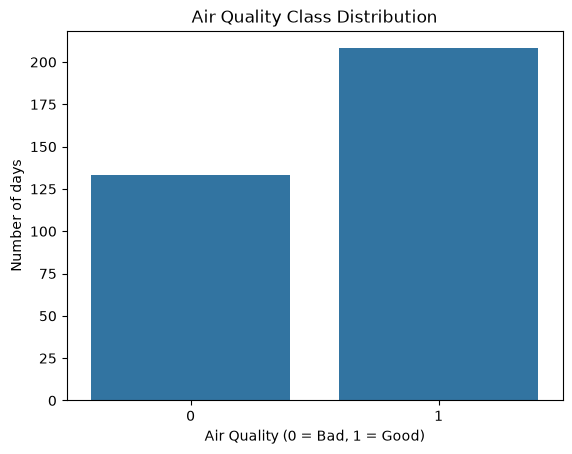

In [29]:
sns.countplot(data=daily_df, x='Air_Quality')

plt.title('Air Quality Class Distribution')
plt.xlabel('Air Quality (0 = Bad, 1 = Good)')
plt.ylabel('Number of days')
plt.show()

The dataset contains both classes with a relatively balanced distribution

In [30]:
#select x and y
X = daily_df[['NOx', 'RH']].copy()

y = daily_df['Air_Quality']

display(X.head())
display(y.head())

,NOx,RH
0,311.181818,51.140909
1,413.952381,68.280952
2,432.913043,64.034783
3,577.136364,65.318182
4,435.217391,69.082609


0    1
1    1
2    0
3    0
4    0
Name: Air_Quality, dtype: int64

Split data

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [32]:
print(daily_df['Air_Quality'].value_counts())
print(daily_df[['CO', 'NO2']].describe())
CO_REFERENCE = daily_df['CO'].median()
NO2_REFERENCE = daily_df['NO2'].median()

daily_df['Air_Quality'] = (
    (daily_df['CO'] > CO_REFERENCE) |
    (daily_df['NO2'] > NO2_REFERENCE)
).astype(int)

Air_Quality
1    208
0    133
Name: count, dtype: int64
               CO         NO2
count  341.000000  341.000000
mean     2.163547  112.753864
std      0.858060   33.036728
min      0.100000   38.043478
25%      1.512500   90.333333
50%      2.169565  109.347826
75%      2.678261  131.782609
max      5.650000  218.636364


In [33]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (272, 2)
X_test: (69, 2)
y_train: (272,)
y_test: (69,)


standarize before KNN

In [34]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

KNN with different hyperparameter k

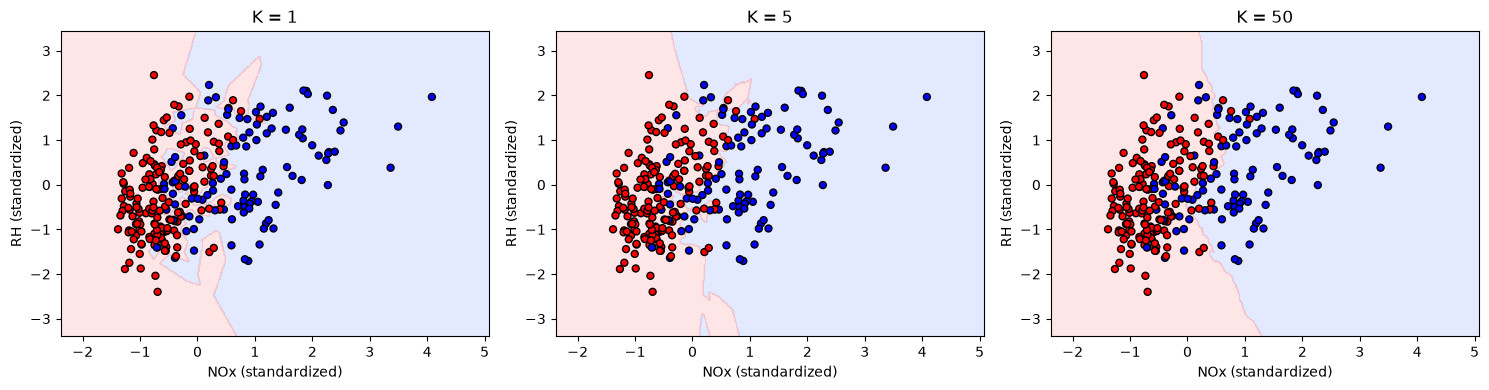

In [35]:
# K values to visualize
k_values = [1, 5, 50]

# Create mesh
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Colors
cmap_background = ListedColormap(['#b9caff', '#ffc1c1'])
cmap_points = ListedColormap(['blue', 'red'])

# Create plots
plt.figure(figsize=(15, 4))

for i, k in enumerate(k_values):

    # Create KNN model
    knn = KNeighborsClassifier(n_neighbors=k)

    # Fit model
    knn.fit(X_train, y_train)

    # Predict classes for mesh points
    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot decision boundary
    plt.subplot(1, 3, i + 1)

    plt.contourf(
        xx, yy, Z,
        alpha=0.4,
        cmap=cmap_background
    )

    # Plot training observations
    plt.scatter(
        X_train[:, 0],
        X_train[:, 1],
        c=y_train,
        cmap=cmap_points,
        edgecolors='black',
        s=25
    )

    plt.title(f'K = {k}')
    plt.xlabel('NOx (standardized)')
    plt.ylabel('RH (standardized)')

plt.tight_layout()
plt.show()

The number of neighbors affects the model's classification performance.

Finding the best k hyperparameter

In [36]:
# Create lists
train_accuracies = []
test_accuracies = []

# Neighbors range
neighbors_range = np.arange(1, 21)

# Loop
for k in neighbors_range:

    # Create KNN model
    knn = KNeighborsClassifier(n_neighbors=k)

    # Fit model
    knn.fit(X_train, y_train)

    # Calculate accuracies
    train_accuracies.append(knn.score(X_train, y_train))
    test_accuracies.append(knn.score(X_test, y_test))

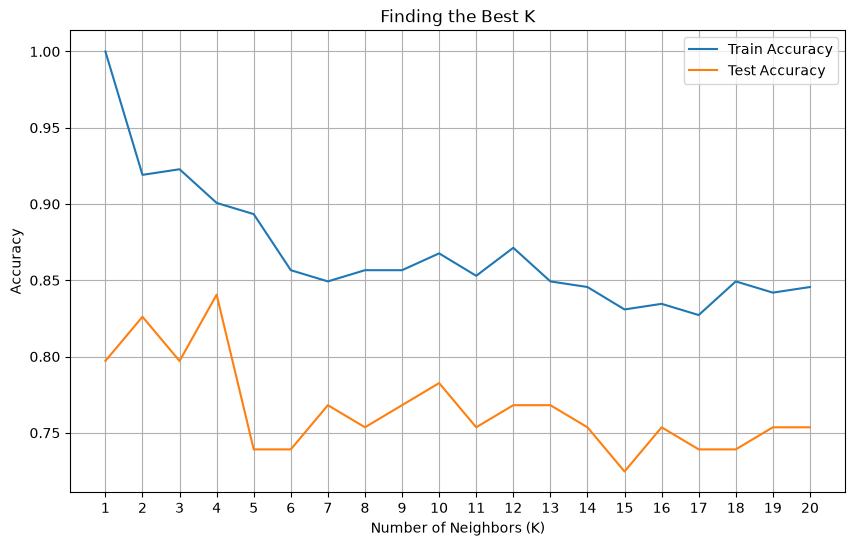

In [37]:
plt.figure(figsize=(10, 6))

plt.plot(neighbors_range, train_accuracies, label='Train Accuracy')
plt.plot(neighbors_range, test_accuracies, label='Test Accuracy')

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('Finding the Best K')

plt.xticks(neighbors_range)
plt.legend()
plt.grid()
plt.show()

In [38]:
knn = KNeighborsClassifier(n_neighbors=4)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Final Test Accuracy:", knn.score(X_test, y_test))

Final Test Accuracy: 0.8405797101449275


The number of neighbors affects the model's classification performance.

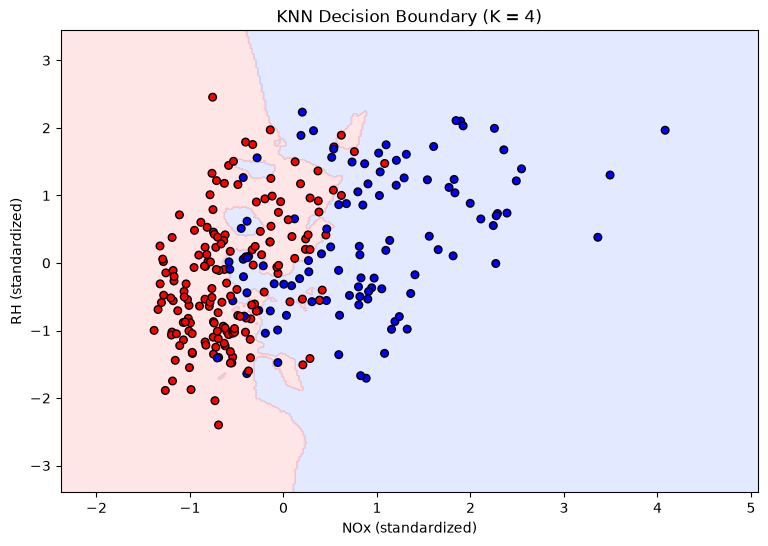

In [39]:
# Create KNN model with the best K
knn = KNeighborsClassifier(n_neighbors=4)

# Train the model
knn.fit(X_train, y_train)

# Create mesh grid
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict classes for mesh points
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Colors
cmap_background = ListedColormap(['#b9caff', '#ffc1c1'])
cmap_points = ListedColormap(['blue', 'red'])

# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, Z,
    alpha=0.4,
    cmap=cmap_background
)

# Plot training observations
plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap=cmap_points,
    edgecolors='black',
    s=30
)

plt.title('KNN Decision Boundary (K = 4)')
plt.xlabel('NOx (standardized)')
plt.ylabel('RH (standardized)')
plt.show()